# Day 2-3 Lab, Part 1: scikit-learn Style ML Basics

**NIAI AI/ML Program · Module 3-4 · Trainer: Anique Atique Alam**

**How this notebook works**
- Cells marked `# TODO` are yours to complete. Cells with `assert` check your work.
- Sections show which lecture part they need: **II** (ML foundations), **III** (linear regression), **IV** (logistic regression).
- All datasets are bundled with scikit-learn, so no network is needed.
- Kernel: `niai-ml` (select it in the top right of JupyterLab).

| Section | Topic | Needs | Time |
|---|---|---|---|
| 1 | The estimator API | II | 15 min |
| 2 | Metrics, baselines, cross-validation | II | 15 min |
| 3 | Pipelines and leakage | II | 10 min |
| 4 | Build your own estimator (gradient descent) | III | 25 min |
| 5 | Polynomial regression and Ridge | III | 15 min |
| 6 | Logistic regression | IV | 20 min |
| 7 | Checkpoint questions | | 5 min |

In [1]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.base import BaseEstimator, RegressorMixin
from sklearn.compose import ColumnTransformer
from sklearn.datasets import load_breast_cancer, load_diabetes, load_iris
from sklearn.dummy import DummyRegressor
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression, LogisticRegression, Ridge
from sklearn.metrics import (confusion_matrix, f1_score, mean_absolute_error,
                             mean_squared_error, precision_score, recall_score,
                             roc_auc_score)
from sklearn.model_selection import GridSearchCV, cross_val_score, train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, PolynomialFeatures, StandardScaler

RANDOM_STATE = 42
plt.rcParams["figure.figsize"] = (6, 3.5)

## 1. The estimator API (Part II)

Every scikit-learn model follows the same contract:

| Method | Meaning |
|---|---|
| `fit(X, y)` | learn from the training data |
| `predict(X)` | produce predictions |
| `score(X, y)` | default quality metric (R² for regressors, accuracy for classifiers) |
| `transform(X)` | (preprocessors) convert data using what `fit` learned |

Learned values end with an underscore: `coef_`, `intercept_`.

We start with the diabetes dataset: 10 numeric features, predict disease progression.

In [2]:
X, y = load_diabetes(return_X_y=True, as_frame=True)
print(X.shape, y.shape)
X.head()

(442, 10) (442,)


,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6
0,0.038076,0.050680,0.061696,0.021872,-0.044223,-0.034821,-0.043401,-0.002592,0.019907,-0.017646
1,-0.001882,-0.044642,-0.051474,-0.026328,-0.008449,-0.019163,0.074412,-0.039493,-0.068332,-0.092204
2,0.085299,0.050680,0.044451,-0.005670,-0.045599,-0.034194,-0.032356,-0.002592,0.002861,-0.025930
3,-0.089063,-0.044642,-0.011595,-0.036656,0.012191,0.024991,-0.036038,0.034309,0.022688,-0.009362
4,0.005383,-0.044642,-0.036385,0.021872,0.003935,0.015596,0.008142,-0.002592,-0.031988,-0.046641


In [3]:
# TODO: split into 80% train / 20% test, using random_state=RANDOM_STATE
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE)

In [4]:
# TODO 1: create a LinearRegression model
model = LinearRegression()

# TODO 2: train it on the training data
model.fit(X_train, y_train)

# TODO 3: predict on the test data
y_pred = model.predict(X_test)

In [5]:
assert X_train.shape[0] == 353
assert model.coef_.shape == (10,)
assert y_pred.shape == y_test.shape
print("R^2 on test:", round(model.score(X_test, y_test), 3))
pd.Series(model.coef_, index=X.columns).sort_values()

R^2 on test: 0.453


s1    -931.488846
sex   -241.964362
age     37.904021
s6      48.670657
s3     163.419983
s4     275.317902
bp     347.703844
s2     518.062277
bmi    542.428759
s5     736.198859
dtype: float64

## 2. Metrics, baselines and cross-validation (Part II)

A score means nothing without a **baseline**. First compute the three regression metrics yourself, then compare to a model that always predicts the training mean.

In [6]:
# TODO: compute by hand with numpy (no sklearn.metrics)
#   MAE  = mean(|error|)      RMSE = sqrt(mean(error^2))
#   R2   = 1 - sum(error^2) / sum((y - mean(y))^2)
err = y_test - y_pred
mae = np.mean(np.abs(err))
rmse = np.sqrt(np.mean(err ** 2))
r2 = 1 - np.sum(err ** 2) / np.sum((y_test - np.mean(y_test)) ** 2)

In [7]:
assert np.isclose(mae, mean_absolute_error(y_test, y_pred))
assert np.isclose(rmse, np.sqrt(mean_squared_error(y_test, y_pred)))
assert np.isclose(r2, model.score(X_test, y_test))
print(f"MAE {mae:.1f}   RMSE {rmse:.1f}   R2 {r2:.3f}")

MAE 42.8   RMSE 53.9   R2 0.453


In [8]:
# TODO: baseline = DummyRegressor(strategy="mean"), fit on the training data
baseline = DummyRegressor(strategy="mean")
baseline.fit(X_train, y_train)
base_r2 = baseline.score(X_test, y_test)

In [9]:
assert base_r2 < 0.05, "a mean predictor should have R^2 near 0"
assert model.score(X_test, y_test) > base_r2
print(f"baseline R2 {base_r2:.3f}  vs  model R2 {model.score(X_test, y_test):.3f}")

baseline R2 -0.012  vs  model R2 0.453


One split can be lucky or unlucky. **Cross-validation** averages over several splits.

In [10]:
# TODO: 5-fold cross-validated R^2 for a fresh LinearRegression on the FULL X, y
scores = cross_val_score(LinearRegression(), X, y, cv=5, scoring="r2")

In [11]:
assert len(scores) == 5
print("fold scores:", scores.round(3))
print(f"mean {scores.mean():.3f} +/- {scores.std():.3f}")

fold scores: [0.43  0.523 0.483 0.426 0.55 ]
mean 0.482 +/- 0.049


## 3. Pipelines and leakage (Part II)

Scalers and imputers **learn** statistics. If they learn them from the whole dataset, test information leaks into training. A `Pipeline` keeps preprocessing and model together so it is refit correctly each time.

In [12]:
Xc, yc = load_breast_cancer(return_X_y=True, as_frame=True)
Xc_tr, Xc_te, yc_tr, yc_te = train_test_split(
    Xc, yc, test_size=0.2, stratify=yc, random_state=RANDOM_STATE)

scaler_all = StandardScaler().fit(Xc)      # WRONG: has seen the test rows
# TODO: the RIGHT way: fit a scaler on the training rows only
scaler_train = StandardScaler().fit(Xc_tr)

In [13]:
leak_gap = np.abs(scaler_all.mean_ - scaler_train.mean_).max()
assert leak_gap > 0
print("largest difference in a learned mean:", round(leak_gap, 3))

largest difference in a learned mean: 11.557


In [14]:
# TODO: build a pipeline: StandardScaler then LogisticRegression(max_iter=1000)
pipe = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))
pipe.fit(Xc_tr, yc_tr)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('standardscaler', ...), ('logisticregression', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](30,)","['mean radius','mean texture','mean perimeter',...,'worst concave points', 'worst symmetry','worst fractal dimension']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,30
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True


In [15]:
assert isinstance(pipe.steps[0][1], StandardScaler)
assert pipe.score(Xc_te, yc_te) > 0.95
print("test accuracy:", round(pipe.score(Xc_te, yc_te), 3))

test accuracy: 0.982


Real tables mix numeric and categorical columns, with missing values. `ColumnTransformer` applies the right steps to the right columns, which is exactly what your `quakes` project does.

In [16]:
df_mixed = pd.DataFrame({
    "age":    [25, 32, np.nan, 41, 29, 55],
    "income": [40, 52, 61, np.nan, 45, 90],
    "city":   ["Lahore", "Karachi", "Lahore", np.nan, "Quetta", "Karachi"],
})

# TODO: numeric (age, income): median imputation, then StandardScaler
#       nominal (city): most-frequent imputation, then OneHotEncoder(handle_unknown="ignore", sparse_output=False)
numeric = make_pipeline(SimpleImputer(strategy="median"), StandardScaler())
nominal = make_pipeline(SimpleImputer(strategy="most_frequent"),
                        OneHotEncoder(handle_unknown="ignore", sparse_output=False))
prep = ColumnTransformer([("num", numeric, ["age", "income"]),
                          ("nom", nominal, ["city"])])
Xt = prep.fit_transform(df_mixed)

In [17]:
assert Xt.shape == (6, 5), f"expected 2 numeric + 3 city columns, got {Xt.shape}"
assert not np.isnan(Xt).any()
print(prep.get_feature_names_out())

['num__age' 'num__income' 'nom__city_Karachi' 'nom__city_Lahore'
 'nom__city_Quetta']


## 4. Build your own estimator: gradient descent (Part III)

Model: $\hat y = \mathbf{x}^\top \mathbf{w} + b$. Loss: $J = \frac{1}{2m}\sum_i (\hat y_i - y_i)^2$.

Gradients: $\frac{\partial J}{\partial w_j} = \frac{1}{m}\sum_i (\hat y_i - y_i)\,x_{ij}$ and $\frac{\partial J}{\partial b} = \frac{1}{m}\sum_i (\hat y_i - y_i)$.

Update: $w_j \leftarrow w_j - \alpha \,\partial J / \partial w_j$.

You will write the gradient twice (loops, then vectorized), check they agree, time them, and wrap the vectorized one in a scikit-learn style class.

In [18]:
rng = np.random.default_rng(RANDOM_STATE)
X_syn = rng.normal(size=(500, 3))
w_true, b_true = np.array([2.0, -1.0, 0.5]), 3.0
y_syn = X_syn @ w_true + b_true + rng.normal(0, 0.5, 500)

In [19]:
def gradient_loop(X, y, w, b):
    """Gradient of J using plain Python loops. Returns (grad_w, grad_b)."""
    m, n = X.shape
    grad_w = np.zeros(n)
    grad_b = 0.0
    for i in range(m):
        # TODO: prediction for sample i, using a loop over features j
        pred = b
        for j in range(n):
            pred += X[i, j] * w[j]
        err = pred - y[i]
        # TODO: add this sample's contribution to grad_w[j] (every j) and to grad_b
        for j in range(n):
            grad_w[j] += err * X[i, j]
        grad_b += err
    return grad_w / m, grad_b / m

In [20]:
def gradient_vec(X, y, w, b):
    """Same gradient with NO Python loops. Returns (grad_w, grad_b)."""
    # TODO: err = X @ w + b - y ; grad_w = X.T @ err / m ; grad_b = err.mean()
    m = X.shape[0]
    err = X @ w + b - y
    grad_w = X.T @ err / m
    grad_b = err.mean()
    return grad_w, grad_b

In [21]:
w0, b0 = rng.normal(size=3), 1.0
gw_l, gb_l = gradient_loop(X_syn, y_syn, w0, b0)
gw_v, gb_v = gradient_vec(X_syn, y_syn, w0, b0)
assert np.allclose(gw_l, gw_v) and np.isclose(gb_l, gb_v), "loop and vectorized gradients differ"
print("gradients agree")

gradients agree


In [22]:
X_big, y_big = rng.normal(size=(20000, 5)), rng.normal(size=20000)
w5 = np.zeros(5)

t0 = time.perf_counter(); gradient_loop(X_big, y_big, w5, 0.0); t_loop = time.perf_counter() - t0
t0 = time.perf_counter(); gradient_vec(X_big, y_big, w5, 0.0);  t_vec = time.perf_counter() - t0
print(f"loop {t_loop*1000:.1f} ms   vectorized {t_vec*1000:.2f} ms   speedup x{t_loop/t_vec:.0f}")
assert t_vec < t_loop

loop 88.1 ms   vectorized 0.91 ms   speedup x97


In [23]:
class GDLinearRegression(BaseEstimator, RegressorMixin):
    def __init__(self, lr=0.1, n_iter=1000):
        self.lr = lr
        self.n_iter = n_iter

    def fit(self, X, y):
        X = np.asarray(X, dtype=float)
        y = np.asarray(y, dtype=float)
        w, b = np.zeros(X.shape[1]), 0.0
        self.loss_history_ = []
        for _ in range(self.n_iter):
            # TODO 1: append the current loss (1/2m) * sum(err**2) to loss_history_
            err = X @ w + b - y
            self.loss_history_.append(np.sum(err ** 2) / (2 * len(y)))
            # TODO 2: get gradients from gradient_vec, then update w and b
            grad_w, grad_b = gradient_vec(X, y, w, b)
            w = w - self.lr * grad_w
            b = b - self.lr * grad_b
        self.coef_, self.intercept_ = w, b
        return self

    def predict(self, X):
        # TODO: X @ coef_ + intercept_
        return np.asarray(X, dtype=float) @ self.coef_ + self.intercept_

In [24]:
gd = GDLinearRegression(lr=0.1, n_iter=1000).fit(X_syn, y_syn)
ref = LinearRegression().fit(X_syn, y_syn)
assert gd.loss_history_[-1] < gd.loss_history_[0]
assert np.allclose(gd.coef_, ref.coef_, atol=0.02), "should match the closed-form solution"
print("GD coef:", gd.coef_.round(3), " sklearn coef:", ref.coef_.round(3))

GD coef: [ 1.956 -0.989  0.52 ]  sklearn coef: [ 1.956 -0.989  0.52 ]


**Learning rate.** Fit with three learning rates and watch the loss curve. One is too small, one is right, one is too large.

In [25]:
learning_rates = [0.001, 0.1, 2.5]
histories = {}
for lr in learning_rates:
    # TODO: fit GDLinearRegression(lr=lr, n_iter=60) on X_syn, y_syn and store loss_history_ in histories[lr]
    histories[lr] = GDLinearRegression(lr=lr, n_iter=60).fit(X_syn, y_syn).loss_history_

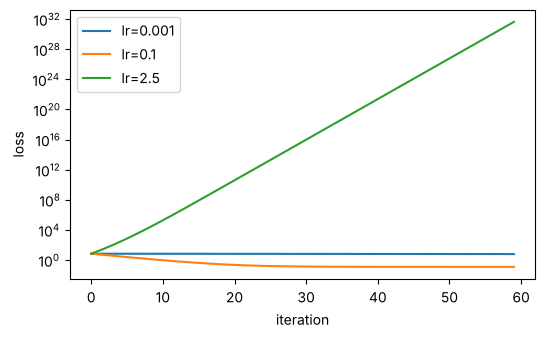

In [26]:
for lr, h in histories.items():
    plt.plot(h, label=f"lr={lr}")
plt.yscale("log"); plt.xlabel("iteration"); plt.ylabel("loss"); plt.legend(); plt.show()
assert histories[0.1][-1] < histories[0.001][-1]
assert histories[2.5][-1] > histories[2.5][0], "lr=2.5 should diverge"

**Feature scaling.** The same algorithm on features with very different scales:

In [27]:
scales = np.array([1.0, 50.0, 0.1])
X_raw = X_syn * scales
y_raw = X_raw @ np.array([2.0, -0.04, 10.0]) + 3.0 + rng.normal(0, 0.5, 500)
X_scaled = StandardScaler().fit_transform(X_raw)

# TODO: fit on the UNSCALED data with lr=1e-4, n_iter=500 (a larger lr would blow up the big feature)
#       and on the SCALED data with lr=0.1, n_iter=500. Keep the fitted models.
gd_raw = GDLinearRegression(lr=1e-4, n_iter=500).fit(X_raw, y_raw)
gd_scaled = GDLinearRegression(lr=0.1, n_iter=500).fit(X_scaled, y_raw)

In [28]:
print(f"final loss unscaled {gd_raw.loss_history_[-1]:.3f}   scaled {gd_scaled.loss_history_[-1]:.3f}")
assert gd_scaled.loss_history_[-1] < gd_raw.loss_history_[-1] / 10

final loss unscaled 6.530   scaled 0.130


## 5. Polynomial regression and Ridge (Part III)

A polynomial model is still *linear in the weights*: expand the features ($x, x^2, x^3, \dots$), then fit a linear model. The degree controls flexibility.

In [29]:
rng = np.random.default_rng(1)
x = np.sort(rng.uniform(0, 2 * np.pi, 60))
y_sin = np.sin(x) + rng.normal(0, 0.3, 60)
Xp = x.reshape(-1, 1)
Xp_tr, Xp_val, yp_tr, yp_val = train_test_split(Xp, y_sin, test_size=0.3, random_state=RANDOM_STATE)

In [30]:
degrees = range(1, 13)
train_err, val_err = [], []
for d in degrees:
    # TODO: pipeline PolynomialFeatures(d, include_bias=False) -> StandardScaler -> LinearRegression
    model_d = make_pipeline(PolynomialFeatures(d, include_bias=False),
                            StandardScaler(), LinearRegression())
    model_d.fit(Xp_tr, yp_tr)
    train_err.append(mean_squared_error(yp_tr, model_d.predict(Xp_tr)))
    val_err.append(mean_squared_error(yp_val, model_d.predict(Xp_val)))
best_degree = degrees[int(np.argmin(val_err))]

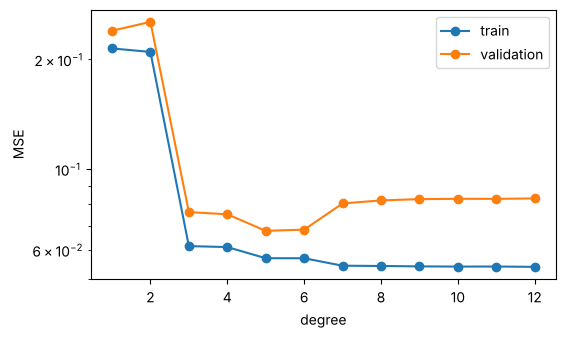

best degree on validation: 5


In [31]:
plt.plot(list(degrees), train_err, "o-", label="train")
plt.plot(list(degrees), val_err, "o-", label="validation")
plt.yscale("log"); plt.xlabel("degree"); plt.ylabel("MSE"); plt.legend(); plt.show()
assert train_err[-1] < train_err[0]
assert 2 <= best_degree <= 9
print("best degree on validation:", best_degree)

**Regularisation.** At degree 12 the plain model chases noise with huge weights. Ridge penalises large weights.

In [32]:
def poly_model(d, est):
    return make_pipeline(PolynomialFeatures(d, include_bias=False), StandardScaler(), est)

plain = poly_model(12, LinearRegression()).fit(Xp_tr, yp_tr)
# TODO: ridge = the same degree-12 model with Ridge(alpha=1.0), fit on the same data
ridge = poly_model(12, Ridge(alpha=1.0)).fit(Xp_tr, yp_tr)

In [33]:
norm_plain = np.linalg.norm(plain[-1].coef_)
norm_ridge = np.linalg.norm(ridge[-1].coef_)
print(f"weight norm  plain {norm_plain:.1f}   ridge {norm_ridge:.1f}")
print(f"validation MSE plain {mean_squared_error(yp_val, plain.predict(Xp_val)):.3f}   "
      f"ridge {mean_squared_error(yp_val, ridge.predict(Xp_val)):.3f}")
assert norm_ridge < norm_plain

weight norm  plain 2345.2   ridge 0.8
validation MSE plain 0.083   ridge 0.163


**Stretch:** Ridge with `alpha=1.0` may over-smooth. Try `alpha` in `[0.001, 0.01, 0.1, 1]` and report which one gives the lowest validation MSE. Regularisation strength is a hyperparameter you tune, not a constant.

In [34]:
# Stretch: tune Ridge alpha on the degree-12 model
alphas = [0.001, 0.01, 0.1, 1]
ridge_val = {}
for a in alphas:
    r = poly_model(12, Ridge(alpha=a)).fit(Xp_tr, yp_tr)
    ridge_val[a] = mean_squared_error(yp_val, r.predict(Xp_val))
best_alpha = min(ridge_val, key=ridge_val.get)
print("validation MSE by alpha:", {a: round(v, 4) for a, v in ridge_val.items()})
print("best alpha:", best_alpha)

validation MSE by alpha: {0.001: 0.0666, 0.01: 0.0709, 0.1: 0.1015, 1: 0.1626}
best alpha: 0.001


**Stretch result:** the lowest validation MSE comes from `alpha=0.001` (0.067), then 0.01 (0.071), 0.1 (0.102) and 1.0 (0.163). So `alpha=1.0` was indeed too strong: it over-smooths and is even worse than the unregularised degree-12 model (0.083), while the smallest alpha is better than both. The best value sits at the edge of the grid, so an even smaller alpha might do slightly better, and with only 18 validation points the differences between the two smallest alphas are small.

## 6. Logistic regression (Part IV)

Breast cancer data. We treat **malignant as the positive class** (1), because missing a malignant case is the costly error.

In [35]:
yb = (yc == 0).astype(int)          # 1 = malignant
Xb_tr, Xb_te, yb_tr, yb_te = train_test_split(
    Xc, yb, test_size=0.2, stratify=yb, random_state=RANDOM_STATE)

# TODO: pipeline StandardScaler -> LogisticRegression(max_iter=1000); fit on the training data
clf = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))
clf.fit(Xb_tr, yb_tr)
# TODO: probability of the positive class for the test rows
proba = clf.predict_proba(Xb_te)[:, 1]

In [36]:
assert proba.shape == (len(Xb_te),)
auc = roc_auc_score(yb_te, proba)
assert auc > 0.95
print("ROC-AUC:", round(auc, 4))

ROC-AUC: 0.996


In [37]:
pred = (proba >= 0.5).astype(int)
# TODO: confusion matrix, precision, recall and F1 for `pred` (use sklearn.metrics)
cm = confusion_matrix(yb_te, pred)
precision = precision_score(yb_te, pred)
recall = recall_score(yb_te, pred)
f1 = f1_score(yb_te, pred)

In [38]:
assert cm.shape == (2, 2)
print(cm)
print(f"precision {precision:.3f}   recall {recall:.3f}   F1 {f1:.3f}")

[[71  1]
 [ 3 39]]
precision 0.975   recall 0.929   F1 0.951


**Threshold sweep.** 0.5 is a default, not a law. Lower thresholds catch more malignant cases and raise false alarms.

In [39]:
rows = []
for t in np.arange(0.1, 0.95, 0.1):
    # TODO: predictions at threshold t, then append {"threshold", "precision", "recall"} to rows
    p_t = (proba >= t).astype(int)
    rows.append({"threshold": t,
                 "precision": precision_score(yb_te, p_t, zero_division=0),
                 "recall": recall_score(yb_te, p_t)})
table = pd.DataFrame(rows).round(3)
table

,threshold,precision,recall
0,0.1,0.891,0.976
1,0.2,0.911,0.976
2,0.3,0.976,0.976
3,0.4,0.976,0.952
4,0.5,0.975,0.929
5,0.6,1.000,0.905
6,0.7,1.000,0.905
7,0.8,1.000,0.857
8,0.9,1.000,0.786


In [40]:
# TODO: the HIGHEST threshold whose recall is still >= 0.95
chosen_threshold = table.loc[table["recall"] >= 0.95, "threshold"].max()

In [41]:
p = (proba >= chosen_threshold).astype(int)
assert recall_score(yb_te, p) >= 0.95
print("chosen threshold:", chosen_threshold)

chosen threshold: 0.4


**Multiclass.** Iris has three classes. `LogisticRegression` handles them directly (softmax).

In [42]:
Xi, yi = load_iris(return_X_y=True)
Xi_tr, Xi_te, yi_tr, yi_te = train_test_split(Xi, yi, test_size=0.3, stratify=yi, random_state=RANDOM_STATE)

# TODO: pipeline StandardScaler -> LogisticRegression(max_iter=1000), fit, then predict on the test set
iris_clf = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))
iris_clf.fit(Xi_tr, yi_tr)
iris_pred = iris_clf.predict(Xi_te)
iris_cm = confusion_matrix(yi_te, iris_pred)

In [43]:
assert iris_cm.shape == (3, 3)
assert (iris_pred == yi_te).mean() > 0.85
probs = iris_clf.predict_proba(Xi_te[:3])
assert np.allclose(probs.sum(axis=1), 1)
print(iris_cm); print(probs.round(3))

[[15  0  0]
 [ 0 14  1]
 [ 0  3 12]]
[[0.    0.101 0.899]
 [0.014 0.789 0.196]
 [0.004 0.62  0.376]]


**Tuning.** `C` is the *inverse* regularisation strength: small `C` means strong regularisation. Search over it with cross-validation. Note the pipeline keeps the scaler inside each fold.

In [44]:
param_grid = {"logisticregression__C": [0.01, 0.1, 1, 10, 100]}
# TODO: GridSearchCV over a StandardScaler -> LogisticRegression pipeline with 5 folds, scoring="roc_auc"; fit on Xb_tr, yb_tr
search = GridSearchCV(make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)),
                      param_grid, cv=5, scoring="roc_auc")
search.fit(Xb_tr, yb_tr)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step..._iter=1000))])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'logisticregression__C': [0.01, 0.1, ...]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'roc_auc'
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",None
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"verbose verbose: int, default=0Controls the verbosity of information printed du

In [45]:
assert search.best_score_ > 0.95
print(search.best_params_, round(search.best_score_, 4))

{'logisticregression__C': 10} 0.9958


## 7. Checkpoint questions

Answer in the cells below (2-3 sentences each).

1. In section 3, what exactly leaked when the scaler was fit on all rows, and why does that make a score untrustworthy?
2. In section 4, why does the loop version lose to the vectorized one, and what happened to the loss with `lr=2.5`?
3. In section 5, what happened to training and validation error as the degree grew, and what did Ridge change?

**Your answer to Q1:**

The scaler's learned statistics (the per-feature mean and standard deviation) were computed from all rows, including the test rows, so information about the test data leaked into the preprocessing; the learned means differed by up to about 11.6 from the train-only scaler. The model is then evaluated on data that has already influenced how the inputs were transformed, so the test set no longer behaves like truly unseen data and the score is optimistically biased. For a plain scaler the effect is small, but the same mistake with imputers or feature selection can inflate scores a lot, which is why the scaler must be fit on the training rows only (a `Pipeline` does this automatically in every fold).

**Your answer to Q2:**

The loop version runs every multiplication and addition in interpreted Python, one element at a time, while the vectorized version does the whole computation as a single NumPy matrix operation in compiled code; on 20,000 rows the loop took about 88 ms versus about 0.9 ms for the vectorized version (roughly 100x faster). With `lr=2.5` the loss went up instead of down: the step is so large that each update overshoots the minimum and lands farther away than before, so the loss diverges (it grows exponentially on the log plot). `lr=0.001` was too small (the loss barely moves in 60 iterations) and `lr=0.1` converged well.

**Your answer to Q3:**

Training error kept falling as the degree grew, because a more flexible polynomial can fit the training points (and their noise) more closely. Validation error was lowest at degree 5 and higher for the more flexible models, which is overfitting, so the best degree is chosen by validation error, not training error. At degree 12 the plain model needed huge weights (weight norm about 2345), while Ridge shrank them to about 0.8; with `alpha=1.0` it over-smoothed (validation MSE 0.163 vs 0.083 for the plain model), but a smaller alpha (0.001) beat the plain model (0.067), so the strength of regularisation has to be tuned.